In [1]:
# Importando bibliotecas

import random
import pandas as pd
import geopandas as gpd
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

## Informações sobre os dados(metadados) podem ser encontradas no site do IBGE, específicamente em:

https://www.ibge.gov.br/estatisticas/sociais/trabalho/22827-censo-demografico-2022.html

In [2]:
# Leitura de arquivos CSV

# Caminho dos dados do IBGE 2022

data_path = Path(r"C:\Users\x432601\Documents\GitHub\ETL_wifi_livre_2026\data\data_ibge_2022\35_SP")

# Caminho dos arquivos CSV
file_01 = data_path / "Domicilios_35_publico.csv"
file_02 = data_path / "Familia_35_publico.csv"
file_03 = data_path / "Mortalidade_35_publico.csv"
file_04 = data_path / "Pessoas_35_publico.csv"


In [3]:


# Leitura de arquivos CSV com amostragem
# Esse passo é necessário par a o carregamento dos dados dadas da pessoas
# Também vamos limitar as variáveis de interesse para reduzir o tamanho do dataset e facilitar a análise.

# Criando função de amostragem para leitura de arquivos CSV grandes

def ler_csv_com_amostragem(caminho_arquivo, tamanho_amostra, selecao_colunas):
    """
    Lê um arquivo CSV grande e retorna uma amostra aleatória de linhas.
    
    Parâmetros:
    caminho_arquivo (str): Caminho para o arquivo CSV.
    tamanho_amostra (int): Número de linhas a serem amostradas.
    selecao_colunas (list): Lista de nomes de colunas a serem selecionadas.

    Retorna:
    pd.DataFrame: DataFrame contendo a amostra aleatória do CSV.
    """
    # 1. Conta o total de linhas no arquivo sem carregar os dados na RAM
    with open(caminho_arquivo, "r", encoding="utf-8") as f:
        total_linhas = sum(1 for _ in f) - 1  # subtrai 1 para desconsiderar o cabeçalho
    
    print(f"Total de linhas no arquivo: {total_linhas}")

    # 2. Sorteia quais índices serão pulados
    random.seed(42)
    linhas_para_pular = set(
        random.sample(
            range(1, total_linhas + 1), total_linhas - tamanho_amostra
        )
    )

    # 3. Lê apenas as linhas mantidas
    df_amostra = pd.read_csv(caminho_arquivo, skiprows=linhas_para_pular, usecols=selecao_colunas, sep=";", encoding="ASCII")
    
    return df_amostra

In [4]:

# Leitura dos arquivos CSV com amostragem

# Colunas de interesse para os dados de domicílios
colunas_domicilios = [
"D0020", # -> Unidade da Federação
"D0100", # -> Controle
"D0110", # -> Peso Amostral
"D0120", # -> Situação do Setor
"D0130", # -> Espécie da Unidade Visitada
"D0140", # -> Situaçao do domicílio
"D0150", # -> Moradores do domicílio, número
"D0160", # -> Crianças do domicílio, número
"D0170", # -> Sexo do morador responsável pelo domicílio
"D0180", # -> Idade da pessoa responsável pelo domicílio, categoria
"D0220", # -> Cômodos no docmicílio, número
"D0230", # -> Cômodos servindo de dormitório no domicílio, número
"D0300", # -> Existencia de água canalizada do domicílio, categoria
"D0330", # -> Acesso à internet, Existência
"D0350", # -> Rendimento domiciliar
"D0360"  # -> Rendimento domiciliar per capita
]

# Colunas de interesse para os dados de pessoas
colunas_pessoas = [
"P0020", # -> Unidade da Federação
"P0100", # -> Controle
#"P0101",# -> Número de ordem do morador
"P0110", # -> Peso Amostral
"P0120", # -> Situação do Setor
"P0130", # -> Espécie da Unidade Visitada
"P0140", # -> Situaçao do domicílio
"P0180", # -> Idade calculada em anos da pessoa, categoria
"P0210", # -> Cor ou raça da pessoa, categoria
"P0220", # -> Pessoa Indígena, categoria 
"P0480", # -> LOCAL DE NASIMENTO DA PESSOA, CATEGORIA
"P0490", # -> UNIDADE DA FEDERAÇÃO DE NASCIMENTO DA PESSOA, CÓDIGO
"P0520", # -> NACIONALIDADE DA PESSOA, CATEGORIA
"P0640", # -> Alfabetização da pessoa, categoria
"P0650", # -> Frequência escolar da pessoa, categoria
"P0660", # -> Curso frequentado pela pessoa, categoria
"P0670", # -> Ano do curso frequentado pela pessoa, categoria
"P0690", # -> Conclusão de outro curos superior de graduação da pessoa, categoria
"P0700", # -> Curso mais elevado frequentado anteriormente da pessoa, categoria
"P0760", # -> Morador, nível de instrução de ensino
"P0790", # -> Anos de estudo da pessoa
"P0840", # -> Existência de trabalho remunerado em dinheiro da pessoa, categoria
"P0860", # -> Existância de bico ou atividade ocasional remunerada da pessoa, categoria
"P0900", # -> Trabalhos da pessoa, categoria
"P0990", # -> Posição na ocupação do trabaho principal da pessoa, categoria
"P1000", # -> Existência de carteira de trabalho assinada no trabalho principal da pessoa, categoria
"P1010", # -> Existência de registro no CNPJ do negócio ou empresa da pessoa, categoria
"P1080", # -> Valor do Rendimento bruto mensal habitual de todos os trabalhos para pessoas de 10 anos ou mais
"P1110", # -> Rendimento recebido em todas as fontes
"P1170", # -> Meios de transporte de deslocamento para o local de trabalho da pessoa, categoria 
"P1180", # -> Tempo em que a pessoa leva entre sua casa e o local de trabalho normalmente, categoria
"P1190", # -> Tempo do deslocamento para trabalho, calculado em minutos
"P1210" # -> Quem prestou as informações da pessoam categoria
]

# Dicionário de mapeamento para a tabela de domicílios
mapa_domicilios = {
    "D0020": "uf",
    "D0100": "controle",
    "D0110": "peso_amostral",
    "D0120": "situacao_setor",
    "D0130": "especie_unidade",
    "D0140": "situacao_domicilio",
    "D0150": "num_moradores",
    "D0160": "num_criancas",
    "D0170": "sexo_responsavel",
    "D0180": "idade_responsavel_cat",
    "D0220": "num_comodos",
    "D0230": "num_dormitorios",
    "D0300": "agua_canalizada",
    "D0330": "acesso_internet",
    "D0350": "rendimento_domiciliar",
    "D0360": "rendimento_per_capita",
}

# Dicionário de mapeamento para a tabela de pessoas
mapa_pessoas = {
    "P0020": "uf",
    "P0100": "controle",
    # "P0101": "ordem_morador",
    "P0110": "peso_amostral",
    "P0120": "situacao_setor",
    "P0130": "especie_unidade",
    "P0140": "situacao_domicilio",
    "P0180": "idade_cat",
    "P0210": "cor_raca",
    "P0220": "indigena",
    "P0480": "local_nascimento",
    "P0490": "uf_nascimento",
    "P0520": "nacionalidade",
    "P0640": "alfabetizacao",
    "P0650": "frequencia_escolar",
    "P0660": "curso_frequentado",
    "P0670": "ano_curso",
    "P0690": "outra_graduacao",
    "P0700": "curso_anterior_elevado",
    "P0760": "nivel_instrucao",
    "P0790": "anos_estudo",
    "P0840": "trabalho_remunerado",
    "P0860": "bico_ocasional",
    "P0900": "qtd_trabalhos",
    "P0990": "posicao_ocupacao",
    "P1000": "carteira_assinada",
    "P1010": "registro_cnpj",
    "P1080": "rendimento_trabalhos",
    "P1110": "rendimento_todas_fontes",
    "P1170": "meio_transporte_trabalho",
    "P1180": "tempo_deslocamento_cat",
    "P1190": "tempo_deslocamento_min",
    "P1210": "informante",
}


df_ibge_2022_domicilios = pd.read_csv(file_01, usecols=colunas_domicilios, sep=";", encoding="ASCII", low_memory=False)
df_ibge_2022_familias = pd.read_csv(file_02, nrows=1000, sep=";", encoding="ASCII", low_memory=False)
df_ibge_2022_mortalidade = pd.read_csv(file_03, nrows=1000, sep=";", encoding="ASCII", low_memory=False)
df_ibge_2022_pessoas = ler_csv_com_amostragem(file_04, tamanho_amostra=10000, selecao_colunas=colunas_pessoas)

Total de linhas no arquivo: 3716739


In [5]:
# Verificando estrutura geral do dataframe de domicílios
df_ibge_2022_domicilios.tail()

,D0020,D0100,D0110,D0120,D0130,D0140,D0150,D0160,D0170,D0180,D0220,D0230,D0300,D0330,D0350,D0360
1376928,35,2977765,8.164624,1,1,1,4,1,2.0,9.0,4.0,2.0,1.0,1.0,3435.0,858.75
1376929,35,1053200,15.010947,1,1,1,4,0,1.0,9.0,6.0,3.0,1.0,1.0,6000.0,1500.00
1376930,35,6128383,13.460797,1,1,1,2,0,1.0,17.0,5.0,1.0,1.0,2.0,2424.0,1212.00
1376931,35,143459,5.932774,3,1,1,3,1,1.0,7.0,5.0,2.0,1.0,1.0,8000.0,2666.67
1376932,35,5241846,9.778901,3,1,1,3,0,1.0,14.0,9.0,2.0,1.0,1.0,5000.0,1666.67


In [6]:
# Mineração e tratamento dos dados do IBGE: DOMICÍLIOS 2022

# Verificando os nomes das colunas do DataFrame
nome_variaveis = df_ibge_2022_domicilios.columns.to_list()

# Defina um ou mais prefixos
prefixos_para_remover = ("MD")

# Mantém apenas o que NÃO começa com esses prefixos
nome_variaveis_filtradas = [nv for nv in nome_variaveis if not nv.startswith(prefixos_para_remover)]

# Print do tamanho da lista
print(len(nome_variaveis_filtradas))

df_ibge_2022_domicilios_filtrado = df_ibge_2022_domicilios[nome_variaveis_filtradas]

import math

cols = df_ibge_2022_domicilios_filtrado.columns.to_list()
total = len(cols)

# Define o número de colunas para aproximar uma matriz quadrada
num_cols = math.ceil(math.sqrt(total))

# Divide a lista em blocos (linhas) de tamanho num_cols
linhas = [cols[i : i + num_cols] for i in range(0, total, num_cols)]

# Calcula a largura de cada coluna para manter o alinhamento visual
larguras = [0] * num_cols
for linha in linhas:
    for idx, item in enumerate(linha):
        larguras[idx] = max(larguras[idx], len(str(item)))

# Exibe em formato de matriz alinhada
for linha in linhas:
    linha_formatada = [
        str(item).ljust(larguras[idx]) for idx, item in enumerate(linha)
    ]
    print("  ".join(linha_formatada))


16
D0020  D0100  D0110  D0120
D0130  D0140  D0150  D0160
D0170  D0180  D0220  D0230
D0300  D0330  D0350  D0360


In [7]:
# Printando das listas dos nomes das colunas do DataFrame filtrado
'''print("[")
for elemento in df_ibge_2022_domicilios_filtrado.columns:
    print(f"{elemento},")
print("]")''' 

'print("[")\nfor elemento in df_ibge_2022_domicilios_filtrado.columns:\n    print(f"{elemento},")\nprint("]")'

In [8]:
# Verificando remoções

df_ibge_2022_domicilios_filtrado.head()


,D0020,D0100,D0110,D0120,D0130,D0140,D0150,D0160,D0170,D0180,D0220,D0230,D0300,D0330,D0350,D0360
0,35,3411412,10.332777,1,1,1,1,0,1.0,8.0,10.0,1.0,1.0,1.0,5000.0,5000.00
1,35,4412288,7.211418,1,1,1,3,0,1.0,14.0,3.0,2.0,1.0,1.0,2800.0,933.33
2,35,5935363,10.572520,1,1,1,1,0,2.0,7.0,3.0,1.0,1.0,1.0,2000.0,2000.00
3,35,2898466,11.819337,1,1,1,1,0,2.0,14.0,6.0,1.0,1.0,1.0,0.0,0.00
4,35,4829456,11.959502,1,1,1,2,0,1.0,16.0,6.0,1.0,1.0,2.0,4848.0,2424.00


In [9]:
# Verificando estrutura geral do dataframe de famílias

#df_ibge_2022_familias.head()

In [10]:
# Mineração e tratamento dos dados do IBGE: FAMÍLIAS 2022

# Verificando os nomes das colunas do DataFrame
nome_variaveis = df_ibge_2022_familias.columns.to_list()

# Defina um ou mais prefixos
prefixos_para_remover = ("MF")

# Mantém apenas o que NÃO começa com esses prefixos
nome_variaveis_filtradas = [nv for nv in nome_variaveis if not nv.startswith(prefixos_para_remover)]

# Print do tamanho da lista
print(len(nome_variaveis_filtradas))

df_ibge_2022_familias_filtrado = df_ibge_2022_familias[nome_variaveis_filtradas]

import math

cols = df_ibge_2022_familias_filtrado.columns.to_list()
total = len(cols)

# Define o número de colunas para aproximar uma matriz quadrada
num_cols = math.ceil(math.sqrt(total))

# Divide a lista em blocos (linhas) de tamanho num_cols
linhas = [cols[i : i + num_cols] for i in range(0, total, num_cols)]

# Calcula a largura de cada coluna para manter o alinhamento visual
larguras = [0] * num_cols
for linha in linhas:
    for idx, item in enumerate(linha):
        larguras[idx] = max(larguras[idx], len(str(item)))

# Exibe em formato de matriz alinhada
for linha in linhas:
    linha_formatada = [
        str(item).ljust(larguras[idx]) for idx, item in enumerate(linha)
    ]
    print("  ".join(linha_formatada))

21
F0010  F0020  F0100  F0101  F0110
F0120  F0130  F0140  F0150  F0160
F0170  F0180  F0190  F0200  F0210
F0220  F0230  F0240  F0250  F0260
F0270


In [11]:
# Verificando estrutura geral do dataframe de mortalidade

#df_ibge_2022_mortalidade.head()

In [12]:
# Mineração e tratamento dos dados do IBGE: MORTALIDADE 2022

# Verificando os nomes das colunas do DataFrame
nome_variaveis = df_ibge_2022_mortalidade.columns.to_list()

# Defina um ou mais prefixos
prefixos_para_remover = ("MM")

# Mantém apenas o que NÃO começa com esses prefixos
nome_variaveis_filtradas = [nv for nv in nome_variaveis if not nv.startswith(prefixos_para_remover)]

# Print do tamanho da lista
print(len(nome_variaveis_filtradas))

df_ibge_2022_mortalidade_filtrado = df_ibge_2022_mortalidade[nome_variaveis_filtradas]

import math

cols = df_ibge_2022_mortalidade_filtrado.columns.to_list()
total = len(cols)

# Define o número de colunas para aproximar uma matriz quadrada
num_cols = math.ceil(math.sqrt(total))

# Divide a lista em blocos (linhas) de tamanho num_cols
linhas = [cols[i : i + num_cols] for i in range(0, total, num_cols)]

# Calcula a largura de cada coluna para manter o alinhamento visual
larguras = [0] * num_cols
for linha in linhas:
    for idx, item in enumerate(linha):
        larguras[idx] = max(larguras[idx], len(str(item)))

# Exibe em formato de matriz alinhada
for linha in linhas:
    linha_formatada = [
        str(item).ljust(larguras[idx]) for idx, item in enumerate(linha)
    ]
    print("  ".join(linha_formatada))

11
M0010  M0020  M0100  M0101
M0110  M0120  M0130  M0140
M0150  M0160  M0170


In [13]:
# Verificando estrutura geral do dataframe de pessoas

df_ibge_2022_pessoas.head()

,P0020,P0100,P0110,P0120,P0130,P0140,P0180,P0210,P0220,P0480,...,P0900,P0990,P1000,P1010,P1080,P1110,P1170,P1180,P1190,P1210
0,35,2845402,11.505498,1,1,1,12,4,0,2,...,1.0,8.0,NaN,1.0,3000.0,3000.0,5.0,3.0,30.0,1
1,35,4698814,16.246438,1,1,1,9,1,0,2,...,1.0,4.0,NaN,NaN,2000.0,2000.0,5.0,2.0,15.0,2
2,35,1389608,9.030547,1,1,1,11,4,0,1,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,2
3,35,6425035,6.629815,1,1,1,11,1,0,1,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1
4,35,7193595,7.368970,1,1,1,8,4,0,2,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1


In [14]:
# Mineração e tratamento dos dados do IBGE: PESSOAS 2022

# Verificando os nomes das colunas do DataFrame
nome_variaveis = df_ibge_2022_pessoas.columns.to_list()

# Defina um ou mais prefixos
prefixos_para_remover = ("MP")

# Mantém apenas o que NÃO começa com esses prefixos
nome_variaveis_filtradas = [nv for nv in nome_variaveis if not nv.startswith(prefixos_para_remover)]

# Print do tamanho da lista
print(len(nome_variaveis_filtradas))

df_ibge_2022_pessoas_filtrado = df_ibge_2022_pessoas[nome_variaveis_filtradas]

import math

cols = df_ibge_2022_pessoas_filtrado.columns.to_list()
total = len(cols)

# Define o número de colunas para aproximar uma matriz quadrada
num_cols = math.ceil(math.sqrt(total))

# Divide a lista em blocos (linhas) de tamanho num_cols
linhas = [cols[i : i + num_cols] for i in range(0, total, num_cols)]

# Calcula a largura de cada coluna para manter o alinhamento visual
larguras = [0] * num_cols
for linha in linhas:
    for idx, item in enumerate(linha):
        larguras[idx] = max(larguras[idx], len(str(item)))

# Exibe em formato de matriz alinhada
for linha in linhas:
    linha_formatada = [
        str(item).ljust(larguras[idx]) for idx, item in enumerate(linha)
    ]
    print("  ".join(linha_formatada))

32
P0020  P0100  P0110  P0120  P0130  P0140
P0180  P0210  P0220  P0480  P0490  P0520
P0640  P0650  P0660  P0670  P0690  P0700
P0760  P0790  P0840  P0860  P0900  P0990
P1000  P1010  P1080  P1110  P1170  P1180
P1190  P1210


In [15]:
# Printando das listas dos nomes das colunas do DataFrame filtrado

print("[")
for elemento in df_ibge_2022_pessoas_filtrado.columns:
    print(f'"{elemento}",')
print("]") 

[
"P0020",
"P0100",
"P0110",
"P0120",
"P0130",
"P0140",
"P0180",
"P0210",
"P0220",
"P0480",
"P0490",
"P0520",
"P0640",
"P0650",
"P0660",
"P0670",
"P0690",
"P0700",
"P0760",
"P0790",
"P0840",
"P0860",
"P0900",
"P0990",
"P1000",
"P1010",
"P1080",
"P1110",
"P1170",
"P1180",
"P1190",
"P1210",
]


In [16]:
# Renomeando após a leitura (inplace=True altera o próprio DataFrame sem precisar reatribuir)
df_ibge_2022_domicilios_filtrado.rename(columns=mapa_domicilios, inplace=True)
df_ibge_2022_pessoas_filtrado.rename(columns=mapa_pessoas, inplace=True)

In [17]:
print("Dimensões dados domicílios: ", df_ibge_2022_domicilios_filtrado.shape)
print("Dimensões dados pessoas: ", df_ibge_2022_pessoas_filtrado.shape)
print("Dimensões dados famílias: ", df_ibge_2022_familias_filtrado.shape)
print("Dimensões dados mortalidade: ", df_ibge_2022_mortalidade_filtrado.shape)

Dimensões dados domicílios:  (1376933, 16)
Dimensões dados pessoas:  (10000, 32)
Dimensões dados famílias:  (1000, 21)
Dimensões dados mortalidade:  (1000, 11)


## Usando o Sweetviz foi observado que os dados possuem valores faltantes que talvez devem ser tratados.

In [53]:
# Retirando os outliers.
# Visualização
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
import logging

logging.basicConfig(level=logging.WARNING)

# Método alternativo (IQR) caso o MAD falhe ou gere valores infinitos
def remove_outliers_iqr(df, coluna):
    dados = df[coluna].dropna()
    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)
    iqr = q3 - q1
    
    if iqr == 0 or np.isinf(iqr):
        logging.warning("IQR também é zero ou infinito. Retornando dados sem nulos.")
        return df.dropna(subset=[coluna])
        
    filtro = (df[coluna] >= (q1 - 1.5 * iqr)) & (df[coluna] <= (q3 + 1.5 * iqr))
    return df[filtro]

def remove_outliers_mad(df, coluna, threshold=3.5):
    # 1. Remove NaNs e substitui infinitos por NaN antes de limpar
    df_limpo = df.replace([np.inf, -np.inf], np.nan).dropna(subset=[coluna])
    dados = df_limpo[coluna]

    if dados.empty:
        logging.warning(f"A coluna '{coluna}' não possui dados válidos após limpeza.")
        return df_limpo

    try:
        # Força o NumPy a lançar FloatingPointError/OverflowError em vez de apenas avisar
        with np.errstate(over='raise', invalid='raise', divide='raise'):
            mediana = np.median(dados)
            mad = median_abs_deviation(dados, nan_policy='omit')

            if mad == 0 or np.isnan(mad):
                logging.warning("MAD igual a 0 ou NaN. Retornando dataset sem filtro de outliers.")
                return df_limpo

            z_scores_modificados = 0.6745 * (dados - mediana) / mad
            
            # Verifica se algum resultado virou infinito mesmo sem estourar erro
            if np.any(np.isinf(z_scores_modificados)):
                raise OverflowError("Z-scores modificados geraram valores infinitos.")

            df_filtrado = df_limpo[np.abs(z_scores_modificados) < threshold]
            
            if df_filtrado.empty:
                raise ValueError("O filtro MAD removeu 100% dos dados.")
                
            return df_filtrado

    except (OverflowError, FloatingPointError, ValueError) as e:
        logging.warning(f"Exceção detectada no cálculo do MAD ({e}). Usando método alternativo (IQR)...")
        return remove_outliers_iqr(df_limpo, coluna)

def plot_hist(name_sample, data_frame, colInt : str, teste=False, plot_simetria=True):
    lista_dados = np.array(data_frame[colInt].to_list())
    n_total = len(lista_dados)
    k = int(k_sturge(n_total))

    # --- Lógica do Histograma ---
    amplitude = max(lista_dados) - min(lista_dados)
    bin_width = amplitude / k
    lista_ordenada = np.sort(lista_dados)

    tabela = []
    valor_min = min(lista_dados)

    for i in range(k):
        valor_max = valor_min + bin_width
        if i == k - 1:
            cont = np.sum((lista_ordenada >= valor_min) & (lista_ordenada <= valor_max))
        else:
            cont = np.sum((lista_ordenada >= valor_min) & (lista_ordenada < valor_max))

        freq_i = cont / n_total
        dens_i = freq_i / bin_width
        tabela.append([f"[{valor_min:.2f},{valor_max:.2f})", cont, freq_i, dens_i])
        valor_min = valor_max

    # --- Lógica de Simetria (Tratando Par/Ímpar) ---
    mediana = np.median(lista_ordenada)
    # Se n é ímpar, removemos a mediana exata para parear os lados
    # Se n é par, dividimos o array exatamente ao meio
    m = n_total // 2

    # u_i: distâncias da mediana para os menores valores (em ordem crescente de distância)
    # v_i: distâncias dos maiores valores para a mediana (em ordem crescente de distância)
    abaixo_mediana = lista_ordenada[:m]
    acima_mediana = lista_ordenada[-m:]

    u_i = mediana - abaixo_mediana[::-1] # Inverte para ter a menor distância primeiro
    v_i = acima_mediana - mediana

    # --- Plotagem do Histograma ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6)) if plot_simetria else (plt.figure(figsize=(10,6)), plt.gca())

    intervalos = [linha[0] for linha in tabela]
    densidades = [linha[3] for linha in tabela]
    contagens = [linha[1] for linha in tabela]

    bars = ax1.bar(intervalos, densidades, width=1.0, edgecolor='black', color='skyblue')
    ax1.set_title('Histograma de Densidade')
    ax1.set_xlabel('Intervalos de Classes')
    ax1.set_ylabel('Densidade')
    ax1.tick_params(axis='x', rotation=45)

    for bar, oc in zip(bars, contagens):
        # Se a contagem for maior que 999, divide por 1000 e formata com 'k'
        # O :.1f mantém 1 casa decimal (ex: 1500 vira 1.5k) e .rstrip('0').rstrip('.') remove zeros extras (ex: 2000 vira 2k)
        texto_barra = f"{oc / 1000:.1f}".rstrip('0').rstrip('.') + "k" if oc > 999 else f"{int(oc)}"
        
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), texto_barra,
                 ha='center', va='bottom', fontweight='bold', color='navy')

    # --- Plotagem da Simetria ---
    if plot_simetria:
        ax2.scatter(u_i, v_i, color='blue', edgecolor='black', marker = ".", alpha=0.7)
        lims = [0, max(ax2.get_xlim()[1], ax2.get_ylim()[1])]
        ax2.plot(lims, lims, 'r--', label="Simetria Perfeita")
        ax2.set_title(f"Gráfico de Simetria (n={n_total})")
        ax2.set_xlabel("Distância à Esquerda (Mediana - $x_{(i)}$)")
        ax2.set_ylabel("Distância à Direita ($x_{(n-i+1)}$ - Mediana)")
        ax2.legend()
        ax2.grid(True, linestyle=':', alpha=0.6)
        ax2.ticklabel_format(style='sci', axis='both', scilimits=(0,0))


    plt.suptitle(f"{name_sample}")
    plt.tight_layout()
    plt.savefig(f"{name_sample}.png")
    plt.show()

    if teste:
        print(f"Mediana: {mediana}")
        print(f"Tamanho dos vetores de simetria: {len(u_i)}")

In [19]:
# Visualizando os primeiros registros do DataFrame de domicílios filtrado
df_ibge_2022_domicilios_filtrado.head()

,uf,controle,peso_amostral,situacao_setor,especie_unidade,situacao_domicilio,num_moradores,num_criancas,sexo_responsavel,idade_responsavel_cat,num_comodos,num_dormitorios,agua_canalizada,acesso_internet,rendimento_domiciliar,rendimento_per_capita
0,35,3411412,10.332777,1,1,1,1,0,1.0,8.0,10.0,1.0,1.0,1.0,5000.0,5000.00
1,35,4412288,7.211418,1,1,1,3,0,1.0,14.0,3.0,2.0,1.0,1.0,2800.0,933.33
2,35,5935363,10.572520,1,1,1,1,0,2.0,7.0,3.0,1.0,1.0,1.0,2000.0,2000.00
3,35,2898466,11.819337,1,1,1,1,0,2.0,14.0,6.0,1.0,1.0,1.0,0.0,0.00
4,35,4829456,11.959502,1,1,1,2,0,1.0,16.0,6.0,1.0,1.0,2.0,4848.0,2424.00


In [20]:
# Descrivendo estatísticas gerais do DataFrame de domicílios filtrado

df_ibge_2022_domicilios_filtrado.describe(include="all")

,uf,controle,peso_amostral,situacao_setor,especie_unidade,situacao_domicilio,num_moradores,num_criancas,sexo_responsavel,idade_responsavel_cat,num_comodos,num_dormitorios,agua_canalizada,acesso_internet,rendimento_domiciliar,rendimento_per_capita
count,1376933.0,1.376933e+06,1.376933e+06,1.376933e+06,1.376933e+06,1.376933e+06,1.376933e+06,1.376933e+06,1.349910e+06,1.349910e+06,1.348571e+06,1.348571e+06,1.348571e+06,1.348571e+06,1.349910e+06,1.349910e+06
mean,35.0,3.904928e+06,1.197277e+01,1.565051e+00,1.103537e+00,1.061990e+00,2.699288e+00,3.259977e-01,1.480335e+00,1.051530e+01,5.679780e+00,1.736798e+00,1.008520e+00,1.107929e+00,5.062206e+03,2.126476e+03
std,0.0,2.252025e+06,7.476001e+00,1.680183e+00,7.092606e-01,2.411374e-01,1.371586e+00,6.447117e-01,5.008159e-01,3.257159e+00,2.131329e+00,7.505727e-01,1.170682e-01,3.102909e-01,1.233843e+04,5.200962e+03
min,35.0,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,35.0,1.955479e+06,6.806469e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,8.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.940000e+03,8.030000e+02
50%,35.0,3.906241e+06,1.051912e+01,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,0.000000e+00,1.000000e+00,1.000000e+01,5.000000e+00,2.000000e+00,1.000000e+00,1.000000e+00,3.350000e+03,1.333330e+03
75%,35.0,5.854152e+06,1.440840e+01,1.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00,0.000000e+00,2.000000e+00,1.300000e+01,7.000000e+00,2.000000e+00,1.000000e+00,1.000000e+00,5.800000e+03,2.333330e+03
max,35.0,7.806706e+06,1.134375e+02,8.000000e+00,6.000000e+00,2.000000e+00,3.600000e+01,1.500000e+01,9.000000e+00,9.900000e+01,2.500000e+01,1.200000e+01,3.000000e+00,2.000000e+00,5.053000e+06,2.526500e+06


In [21]:
# Verificando estrutura geral do dataframe de domicílios filtrado

df_ibge_2022_domicilios_filtrado.info()

<class 'pandas.DataFrame'>
RangeIndex: 1376933 entries, 0 to 1376932
Data columns (total 16 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   uf                     1376933 non-null  int64  
 1   controle               1376933 non-null  int64  
 2   peso_amostral          1376933 non-null  float64
 3   situacao_setor         1376933 non-null  int64  
 4   especie_unidade        1376933 non-null  int64  
 5   situacao_domicilio     1376933 non-null  int64  
 6   num_moradores          1376933 non-null  int64  
 7   num_criancas           1376933 non-null  int64  
 8   sexo_responsavel       1349910 non-null  float64
 9   idade_responsavel_cat  1349910 non-null  float64
 10  num_comodos            1348571 non-null  float64
 11  num_dormitorios        1348571 non-null  float64
 12  agua_canalizada        1348571 non-null  float64
 13  acesso_internet        1348571 non-null  float64
 14  rendimento_domiciliar  134991

In [ ]:
#  Visualizando os primeiros registros do DataFrame de domicílios filtrado e tratando a variável "acesso_internet"

df_ibge_2022_domicilios_filtrado[["rendimento_domiciliar", "acesso_internet"]].head()
df_ibge_2022_domicilios_filtrado["acesso_internet"] = df_ibge_2022_domicilios_filtrado["acesso_internet"].replace({ 2:0 , 9: np.nan})

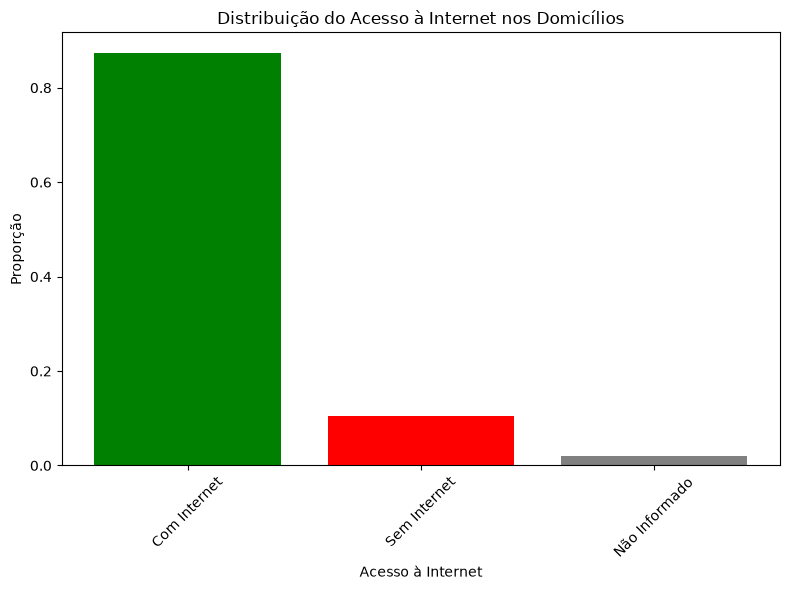

Proporção de domicílios com acesso à internet: 87.37%
Proporção de domicílios sem acesso à internet: 10.57%
Proporção de domicílios com acesso à internet não informado: 2.06%


In [26]:
# Visualização estatística da variável "acesso_internet" após o tratamento

fig, ax = plt.subplots(figsize=(8, 6))
n_dom_com_internet = df_ibge_2022_domicilios_filtrado[df_ibge_2022_domicilios_filtrado["acesso_internet"] == 1].shape[0] / df_ibge_2022_domicilios_filtrado.shape[0]
n_dom_sem_internet = df_ibge_2022_domicilios_filtrado[df_ibge_2022_domicilios_filtrado["acesso_internet"] == 0].shape[0] / df_ibge_2022_domicilios_filtrado.shape[0]
n_dom_nao_informado = df_ibge_2022_domicilios_filtrado["acesso_internet"].isna().sum() / df_ibge_2022_domicilios_filtrado.shape[0]
plt.bar(["Com Internet", "Sem Internet", "Não Informado"], [n_dom_com_internet, n_dom_sem_internet, n_dom_nao_informado], color=["green", "red", "gray"])
plt.xlabel("Acesso à Internet")
plt.ylabel("Proporção")
plt.title("Distribuição do Acesso à Internet nos Domicílios")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Proporção de domicílios com acesso à internet: {n_dom_com_internet:.2%}")
print(f"Proporção de domicílios sem acesso à internet: {n_dom_sem_internet:.2%}")
print(f"Proporção de domicílios com acesso à internet não informado: {n_dom_nao_informado:.2%}")

In [48]:
# Relação de renda e acesso a internet nos domicílios

domicilios_com_internet = df_ibge_2022_domicilios_filtrado[df_ibge_2022_domicilios_filtrado["acesso_internet"] == 1] 
domicilios_sem_internet = df_ibge_2022_domicilios_filtrado[df_ibge_2022_domicilios_filtrado["acesso_internet"] == 0] 
domicilios_nao_informados = df_ibge_2022_domicilios_filtrado[df_ibge_2022_domicilios_filtrado["acesso_internet"].isna()] 

In [49]:
domicilios_com_internet["rendimento_domiciliar"].head()

0    5000.0
1    2800.0
2    2000.0
3       0.0
5    6002.0
Name: rendimento_domiciliar, dtype: float64

float64
0.0
12430.0


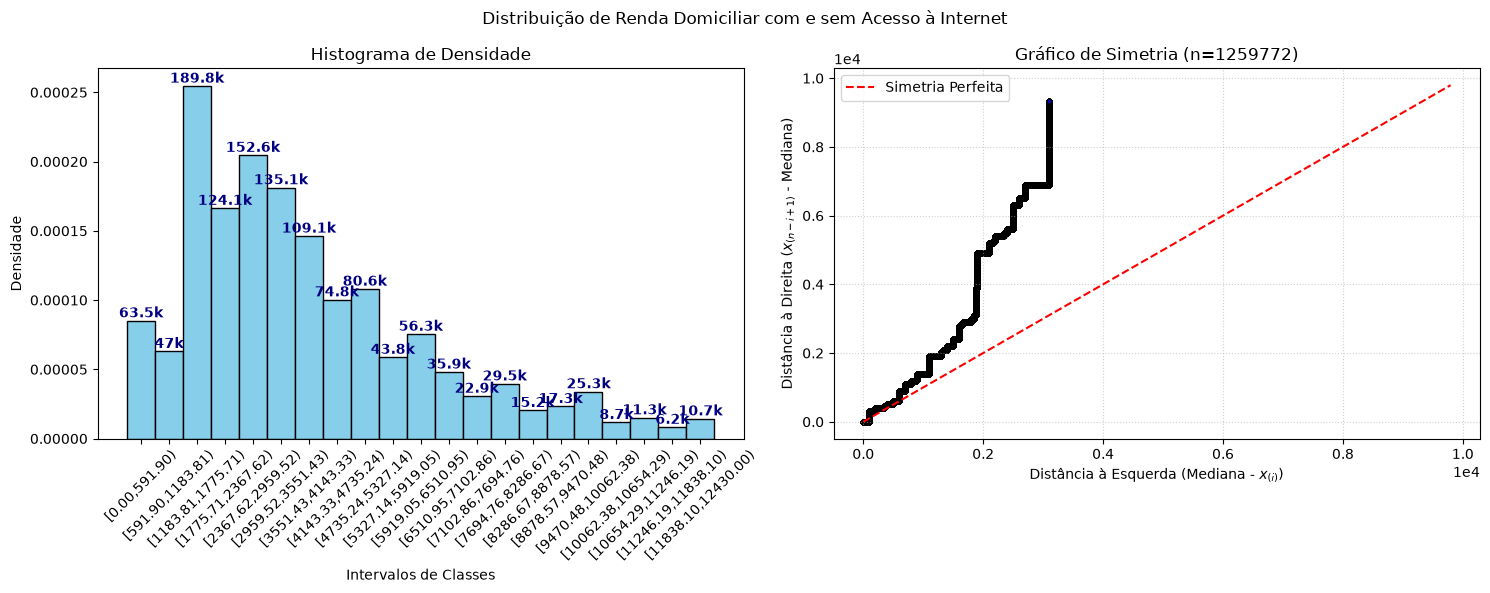

Mediana: 3100.0
Tamanho dos vetores de simetria: 629886


In [54]:
# Plot análise de distribuição de renda domiciliar com e sem acesso à internet

# Testando com remoções de outliers

df_remove = remove_outliers_mad(df_ibge_2022_domicilios_filtrado, "rendimento_domiciliar", threshold=3.5)

print(df_remove["rendimento_domiciliar"].dtype)
print(df_remove["rendimento_domiciliar"].min())
print(df_remove["rendimento_domiciliar"].max())
#df_remove["rendimento_domiciliar"].head()

plot_hist("Distribuição de Renda Domiciliar com e sem Acesso à Internet", df_remove, "rendimento_domiciliar", teste=True, plot_simetria=True)

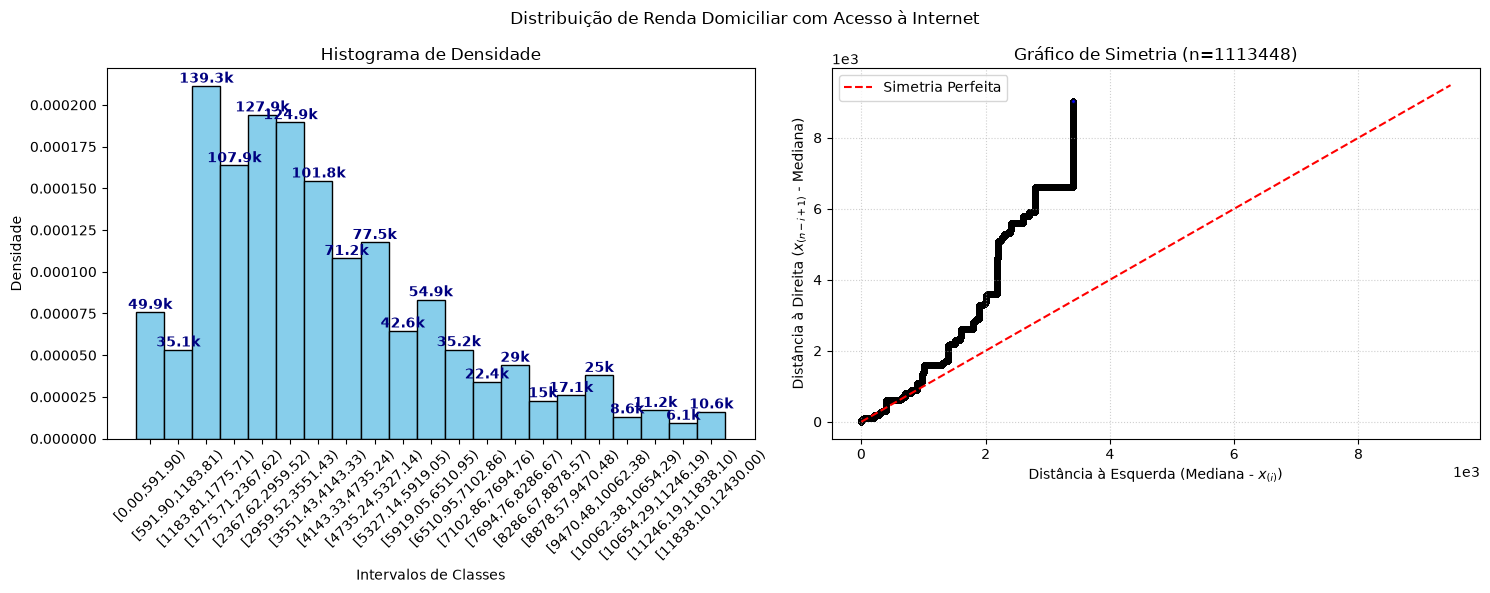

Mediana: 3400.0
Tamanho dos vetores de simetria: 556724


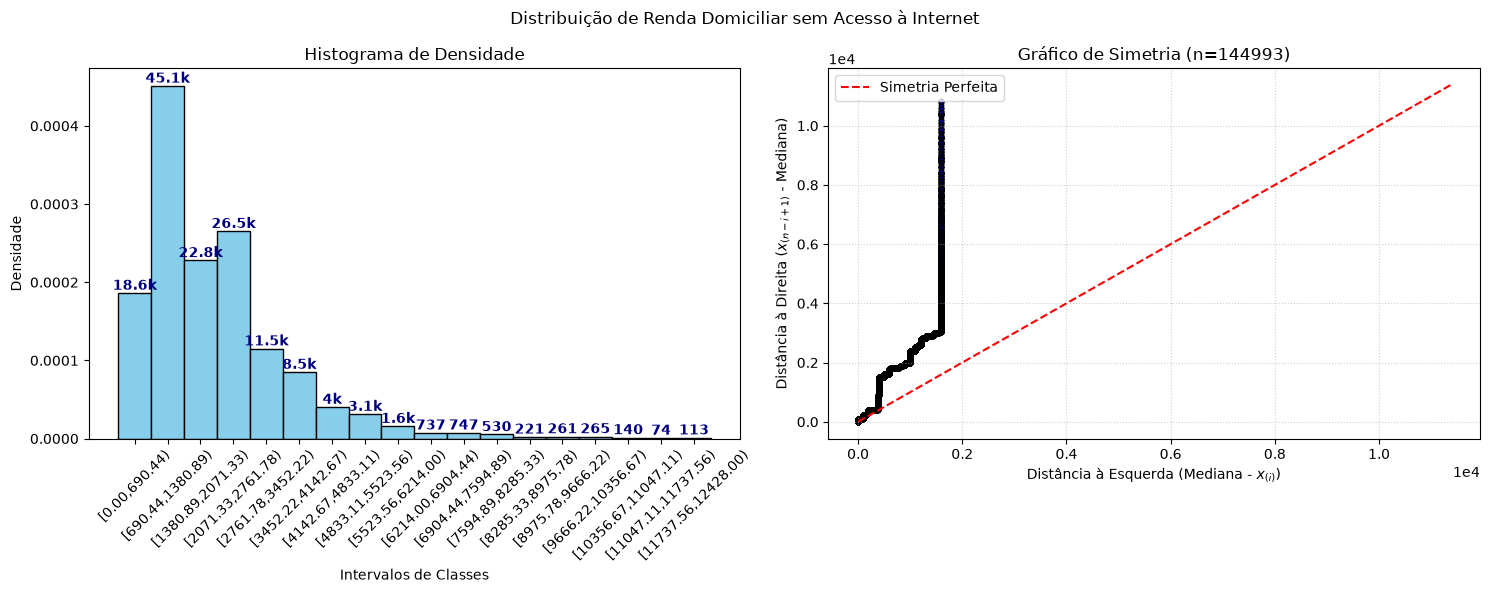

Mediana: 1600.0
Tamanho dos vetores de simetria: 72496


In [55]:
df_remove_com_internet = df_remove[df_remove["acesso_internet"] == 1]
df_remove_sem_internet = df_remove[df_remove["acesso_internet"] == 0]

plot_hist("Distribuição de Renda Domiciliar com Acesso à Internet", df_remove_com_internet, "rendimento_domiciliar", teste=True, plot_simetria=True)
plot_hist("Distribuição de Renda Domiciliar sem Acesso à Internet", df_remove_sem_internet, "rendimento_domiciliar", teste=True, plot_simetria=True)

In [46]:
df_ibge_2022_domicilios_filtrado["rendimento_domiciliar"].info()

<class 'pandas.Series'>
RangeIndex: 1376933 entries, 0 to 1376932
Series name: rendimento_domiciliar
Non-Null Count    Dtype  
--------------    -----  
1349910 non-null  float64
dtypes: float64(1)
memory usage: 10.5 MB


In [18]:
## Importando biblioteca para análise exploratória de dados
#import sweetviz as sv
#
## Análise exploratória de dados (EDA) com Sweetviz
#
#eda_df_ibge_2022_domi=sv.analyze(df_ibge_2022_domicilios_filtrado)
#eda_df_ibge_2022_domi.show_html("eda_df_ibge_2022_domi.html")
#
#eda_df_ibge_2022_pessoas=sv.analyze(df_ibge_2022_pessoas_filtrado)
#eda_df_ibge_2022_pessoas.show_html("eda_df_ibge_2022_pessoas.html")